In [1]:
import functions as f 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("datasets/processed_data.csv",index_col=False)

# Dataset plots

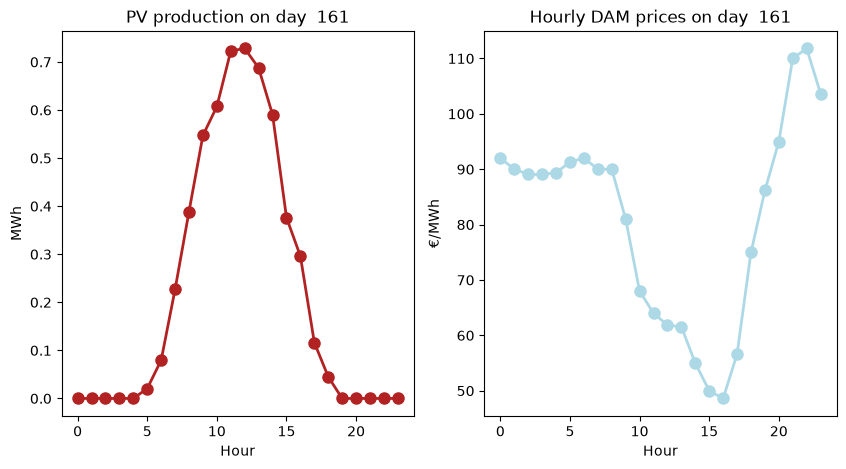

In [3]:
day = np.random.randint(0,365)
day_df = df.iloc[(day*24):((day+1)*24)]

p_actual = day_df['pv_mw'].values
prices = day_df["price_da"].values

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].plot(p_actual, marker='o', linestyle='-', color='firebrick', linewidth=2, markersize=8, label='Actual production')
axes[1].plot(prices, marker='o', linestyle='-', color='lightblue', linewidth=2, markersize=8, label='Point estimate')

axes[0].set(xlabel = "Hour", ylabel = "MWh",
            title="PV production on day  " + str(day+1))
axes[1].set(xlabel = "Hour", ylabel = "€/MWh",
            title="Hourly DAM prices on day  " + str(day+1))

plt.show()


# Testing scenario generation

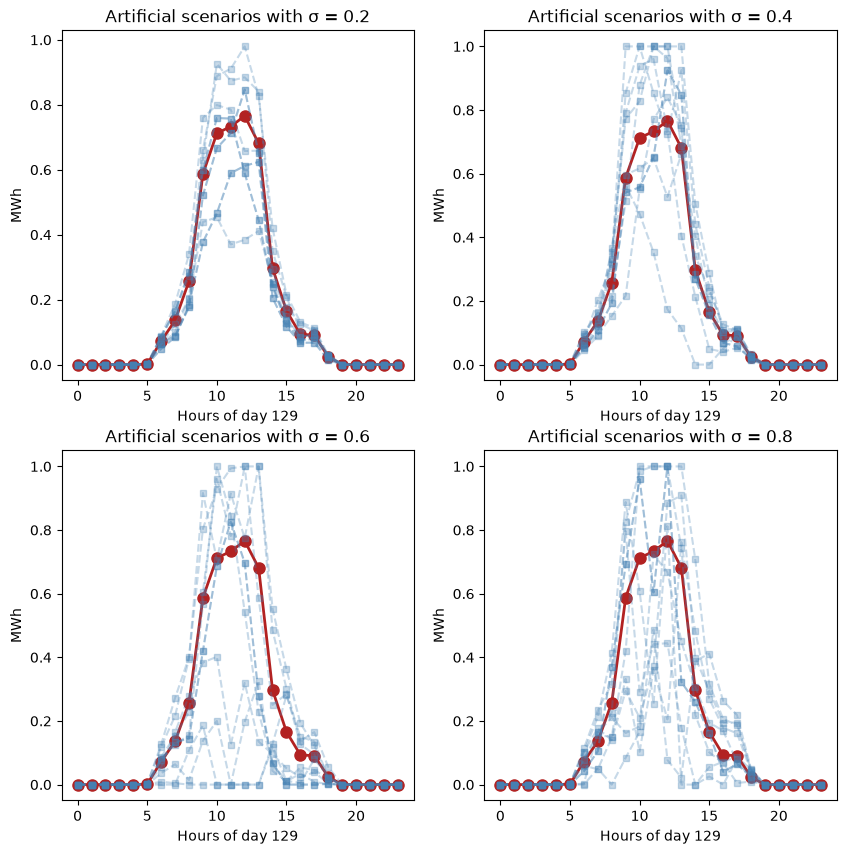

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.flatten()
sigmas = [0.2,0.4,0.6,0.8]

day = np.random.randint(0,365)
day_df = df.iloc[(day*24):((day+1)*24)]

p_actual = day_df['pv_mw'].values

for s in range(4):
    
    scenarios = f.generate_autocorrelated_scenarios(p_actual, sigma=sigmas[s] ,n_scenarios=50, seed=None)

    axes[s].plot(p_actual, marker='o', linestyle='-', color='firebrick', linewidth=2, markersize=8, label='Actual production')
    axes[s].set(xlabel = "Hours of day "+ str(day+1), ylabel = "MWh",
            title="Artificial scenarios with σ = " + str(sigmas[s]))

    for i in np.random.randint(0,scenarios.shape[0],10):
        tag = 'Scenarios' if i == 0 else ""
        axes[s].plot(scenarios[i, :], marker='s', linestyle='--', alpha=0.3, markersize=4, label=tag, color='steelblue')

plt.show()


# Fitting point model for one day

HiGHS 1.11.0:   tech:outlev = 0

"option abs_boundtol 5.551115123125783e-17;"
or "option rel_boundtol 1.5930648777641266e-16;"
will change deduced dual values.



Text(0.5, 1.0, 'Values on day 29')

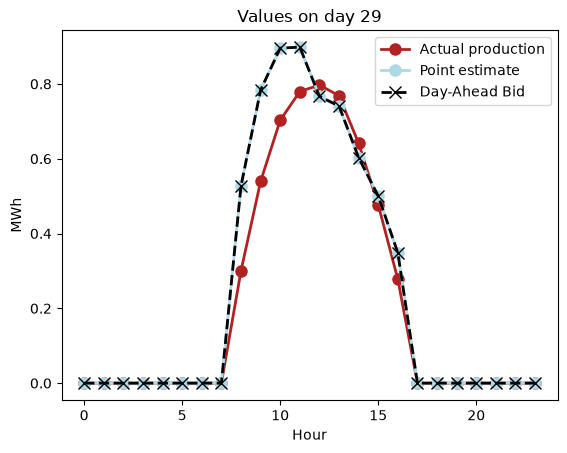

In [ ]:
day = np.random.randint(0,365)
day_df = df.iloc[(day*24):((day+1)*24)]

p_actual = day_df['pv_mw'].values
prices = day_df["price_da"].values

scenario = f.generate_autocorrelated_scenarios(p_actual, n_scenarios=1, seed=None)[0]

p_da = f.da_bid_point(scenario,prices)

plt.plot(p_actual, marker='o', linestyle='-', color='firebrick', linewidth=2, markersize=8, label='Actual production')
plt.plot(scenario, marker='o', linestyle='-', color='lightblue', linewidth=2, markersize=8, label='Point estimate')
plt.plot(p_da, marker='x', linestyle='--', color='black', linewidth=2, markersize=8, label='Day-Ahead Bid')
plt.legend()
plt.xlabel("Hour")
plt.ylabel("MWh")
plt.title("Values on day " + str(day+1))

# Fitting probabilistic model for one day

HiGHS 1.11.0:   tech:outlev = 0


Text(0.5, 1.0, 'Values on day 188')

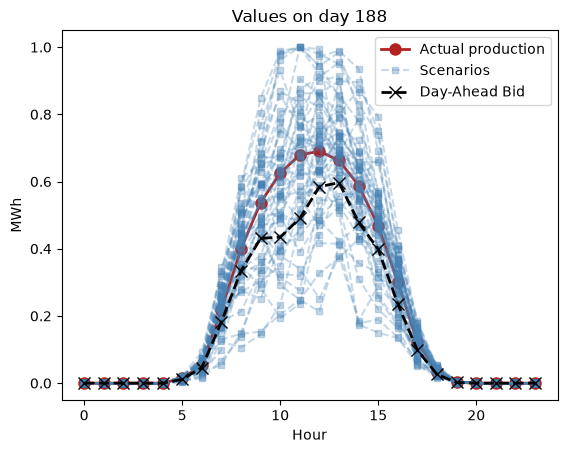

In [ ]:
day = np.random.randint(0,365)
day_df = df.iloc[(day*24):((day+1)*24)]

p_actual = day_df['pv_mw'].values
prices = day_df["price_da"].values

scenarios = f.generate_autocorrelated_scenarios(p_actual, n_scenarios=50, seed=None)

p_da = f.da_bid_probabilistic_standalone(scenarios,prices,c1=-5,c2=15)

plt.plot(p_actual, marker='o', linestyle='-', color='firebrick', linewidth=2, markersize=8, label='Actual production')
for i in range(scenarios.shape[0]):
    tag = 'Scenarios' if i == 0 else ""
    plt.plot(scenarios[i, :], marker='s', linestyle='--', alpha=0.3, markersize=4, label=tag, color='steelblue')
plt.plot(p_da, marker='x', linestyle='--', color='black', linewidth=2, markersize=8, label='Day-Ahead Bid')
plt.legend()
plt.xlabel("Hour")
plt.ylabel("MWh")
plt.title("Values on day " + str(day+1))

# Fitting both models

HiGHS 1.11.0:   tech:outlev = 0
HiGHS 1.11.0:   tech:outlev = 0


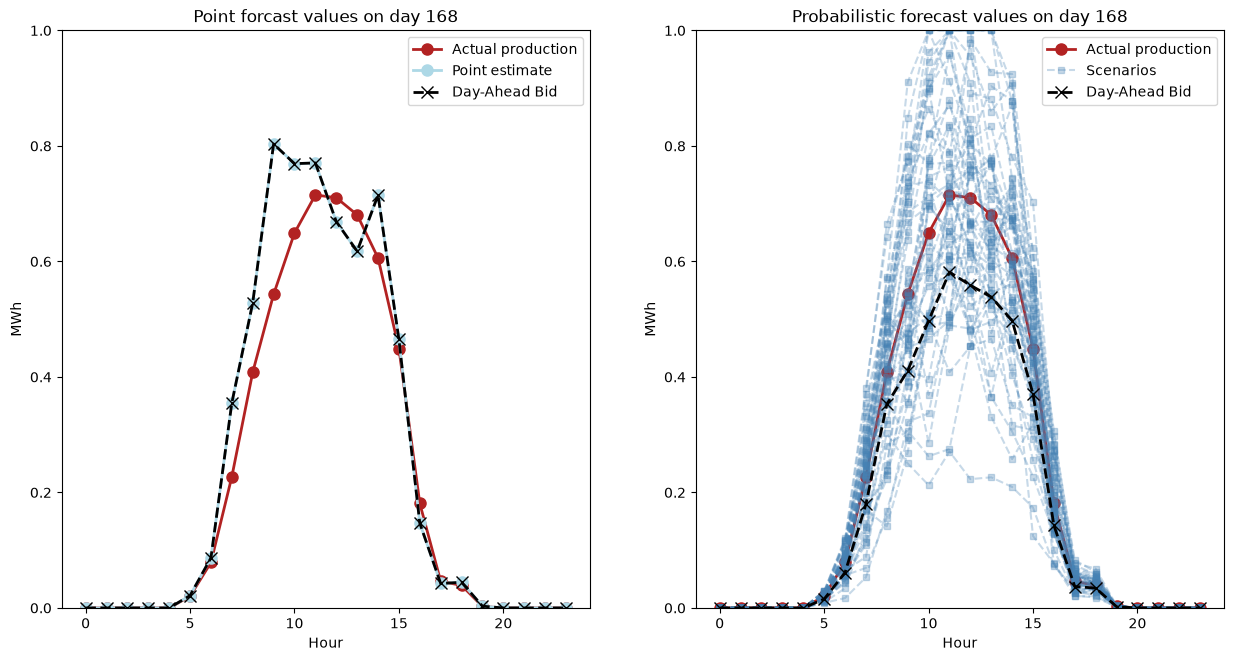

In [21]:
day = np.random.randint(0,365)
day_df = df.iloc[(day*24):((day+1)*24)]

p_actual = day_df['pv_mw'].values
prices = day_df["price_da"].values

scenarios = f.generate_autocorrelated_scenarios(p_actual, n_scenarios=50, seed=None)
point_scenario = scenarios[np.random.randint(0,scenarios.shape[0])]

p_da_point = f.da_bid_point(point_scenario,prices)
p_da_probabilistic = f.da_bid_probabilistic_standalone(scenarios,prices,c1=-5,c2=15)

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

axes[0].plot(p_actual, marker='o', linestyle='-', color='firebrick', linewidth=2, markersize=8, label='Actual production')
axes[0].plot(point_scenario, marker='o', linestyle='-', color='lightblue', linewidth=2, markersize=8, label='Point estimate')
axes[0].plot(p_da_point, marker='x', linestyle='--', color='black', linewidth=2, markersize=8, label='Day-Ahead Bid')
axes[0].set_ylim(0,1)
axes[0].legend()
axes[0].set(xlabel = "Hour", ylabel = "MWh",
            title="Point forcast values on day " + str(day+1))

axes[1].plot(p_actual, marker='o', linestyle='-', color='firebrick', linewidth=2, markersize=8, label='Actual production')
for i in range(scenarios.shape[0]):
    tag = 'Scenarios' if i == 0 else ""
    axes[1].plot(scenarios[i, :], marker='s', linestyle='--', alpha=0.3, markersize=4, label=tag, color='steelblue')
axes[1].plot(p_da_probabilistic, marker='x', linestyle='--', color='black', linewidth=2, markersize=8, label='Day-Ahead Bid')
axes[1].set_ylim(0,1)
axes[1].legend()
axes[1].set(xlabel = "Hour", ylabel = "MWh",
            title="Probabilistic forecast values on day " + str(day+1))

plt.show()

# Fitting and evaluating both models

HiGHS 1.11.0:   tech:outlev = 0

"option abs_boundtol 2.7755575615628914e-17;"
or "option rel_boundtol 1.3468833170643416e-16;"
will change deduced dual values.

HiGHS 1.11.0:   tech:outlev = 0


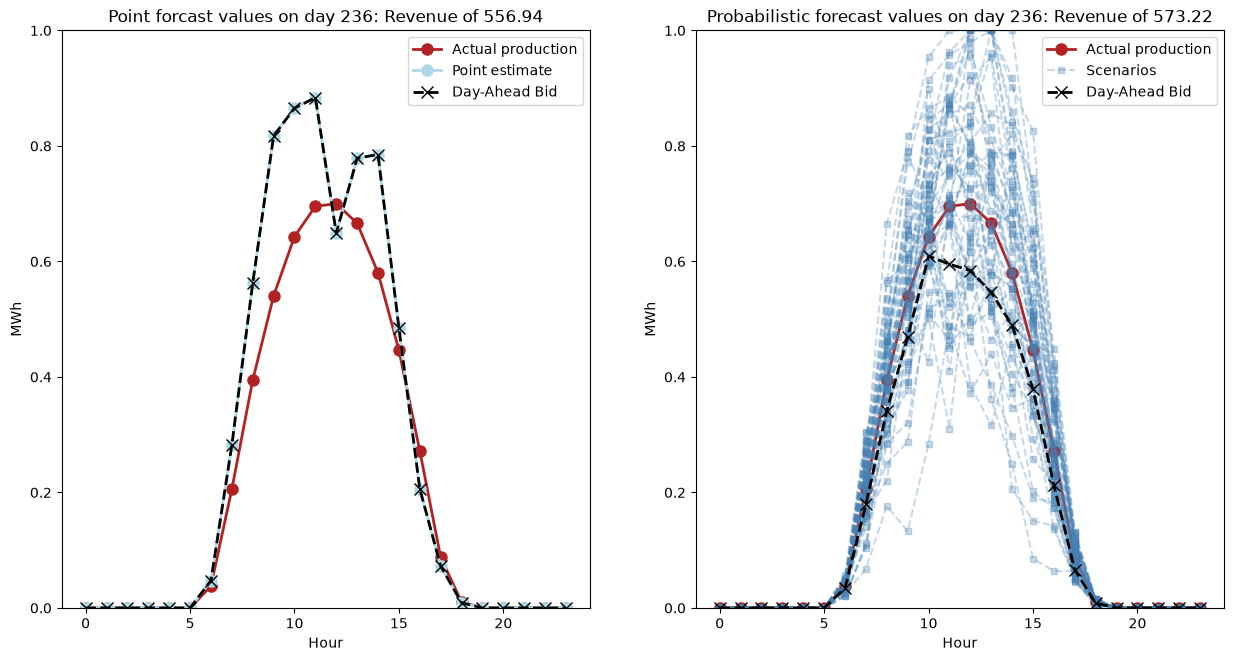

In [10]:
day = np.random.randint(0,365)
day_df = df.iloc[(day*24):((day+1)*24)]

p_actual = day_df['pv_mw'].values
prices = day_df["price_da"].values

scenarios = f.generate_autocorrelated_scenarios(p_actual, n_scenarios=50, seed=None)
point_scenario = scenarios[np.random.randint(0,scenarios.shape[0])]

p_da_point = f.da_bid_point(point_scenario,prices)
p_da_probabilistic = f.da_bid_probabilistic_standalone(scenarios,prices,c1=-5,c2=15)

rev_point = round(f.backtrack_evaluation(p_da_point,p_actual,prices,c1=-5,c2=15),2)
rev_probabilistic = round(f.backtrack_evaluation(p_da_probabilistic,p_actual,prices,c1=-5,c2=15),2)

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

axes[0].plot(p_actual, marker='o', linestyle='-', color='firebrick', linewidth=2, markersize=8, label='Actual production')
axes[0].plot(point_scenario, marker='o', linestyle='-', color='lightblue', linewidth=2, markersize=8, label='Point estimate')
axes[0].plot(p_da_point, marker='x', linestyle='--', color='black', linewidth=2, markersize=8, label='Day-Ahead Bid')
axes[0].set_ylim(0,1)
axes[0].legend()
axes[0].set(xlabel = "Hour", ylabel = "MWh",
            title="Point forcast values on day " + str(day) + ": Revenue of " + str(rev_point))

axes[1].plot(p_actual, marker='o', linestyle='-', color='firebrick', linewidth=2, markersize=8, label='Actual production')
for i in range(scenarios.shape[0]):
    tag = 'Scenarios' if i == 0 else ""
    axes[1].plot(scenarios[i, :], marker='s', linestyle='--', alpha=0.3, markersize=4, label=tag, color='steelblue')
axes[1].plot(p_da_probabilistic, marker='x', linestyle='--', color='black', linewidth=2, markersize=8, label='Day-Ahead Bid')
axes[1].set_ylim(0,1)
axes[1].legend()
axes[1].set(xlabel = "Hour", ylabel = "MWh",
            title="Probabilistic forecast values on day " + str(day) + ": Revenue of " + str(rev_probabilistic))

plt.show()

# Evaluation for all days

In [108]:
results = []
for d in range(365):
    day_df = df.iloc[(d*24):((d+1)*24)]

    p_actual = day_df['pv_mw'].values
    prices = day_df["price_da"].values

    scenarios = f.generate_autocorrelated_scenarios(p_actual, n_scenarios=50, seed=None)
    point_scenario = scenarios[np.random.randint(0,scenarios.shape[0])]

    p_da_point = f.da_bid_point(point_scenario,prices)
    p_da_probabilistic = f.da_bid_probabilistic_standalone(scenarios,prices,c1=-5,c2=15)

    rev_point = round(f.backtrack_evaluation(p_da_point,p_actual,prices,c1=-5,c2=15),2)
    rev_probabilistic = round(f.backtrack_evaluation(p_da_probabilistic,p_actual,prices,c1=-5,c2=15),2)
    results.append({"day":d, "rev_point":rev_point, "rev_probabilistic":rev_probabilistic, "difference":rev_probabilistic-rev_point})

df_results = pd.DataFrame(results)

HiGHS 1.11.0:   tech:outlev = 0
HiGHS 1.11.0:   tech:outlev = 0
HiGHS 1.11.0:   tech:outlev = 0

"option abs_boundtol 2.7755575615628914e-17;"
or "option rel_boundtol 1.6921235719299145e-16;"
will change deduced dual values.

HiGHS 1.11.0:   tech:outlev = 0
HiGHS 1.11.0:   tech:outlev = 0
HiGHS 1.11.0:   tech:outlev = 0
HiGHS 1.11.0:   tech:outlev = 0

"option abs_boundtol 2.7755575615628914e-17;"
or "option rel_boundtol 1.5396768892136022e-16;"
will change deduced dual values.

HiGHS 1.11.0:   tech:outlev = 0
HiGHS 1.11.0:   tech:outlev = 0

"option abs_boundtol 3.469446951953614e-18;"
or "option rel_boundtol 1.8431887028592223e-16;"
will change deduced dual values.

HiGHS 1.11.0:   tech:outlev = 0
HiGHS 1.11.0:   tech:outlev = 0

"option abs_boundtol 3.469446951953614e-18;"
or "option rel_boundtol 1.1811198222762632e-16;"
will change deduced dual values.

HiGHS 1.11.0:   tech:outlev = 0
HiGHS 1.11.0:   tech:outlev = 0

"option abs_boundtol 5.551115123125783e-17;"
or "option rel_bound

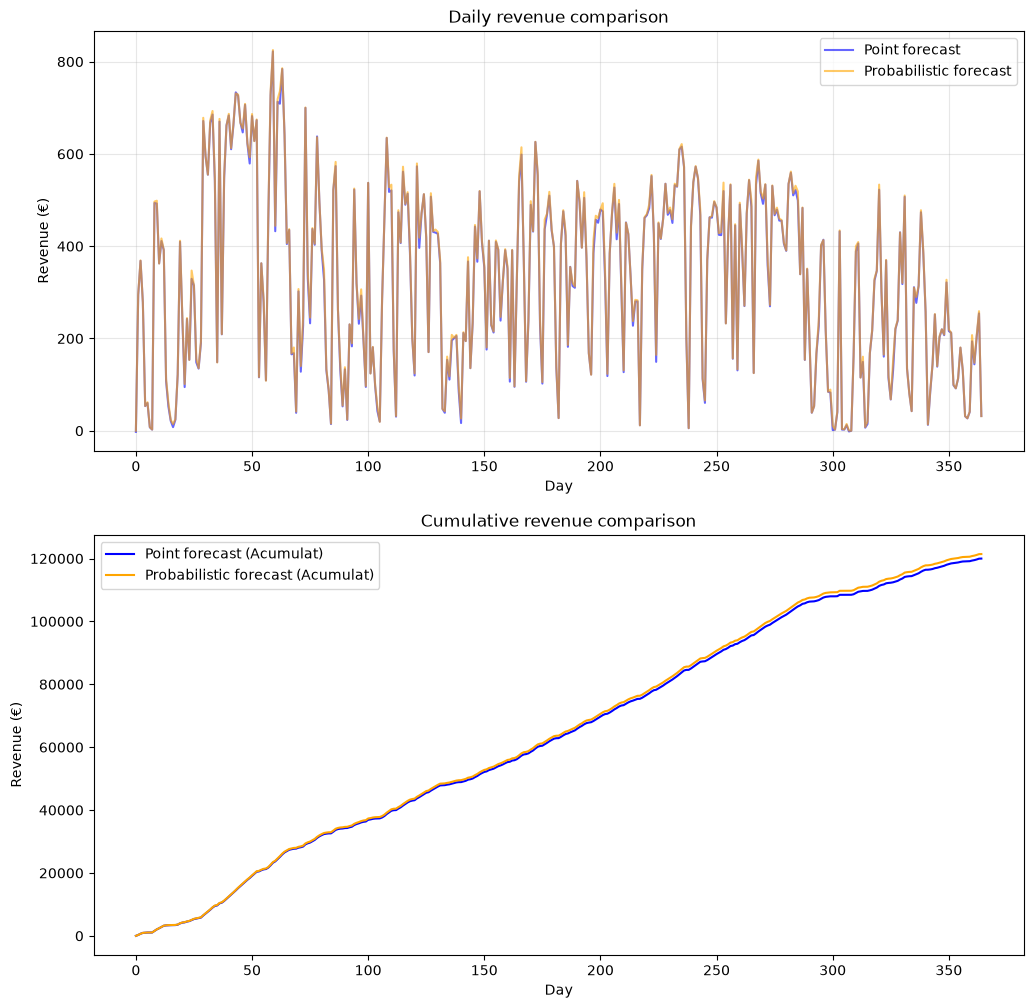

In [109]:
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

axes[0].plot(df_results["day"], df_results["rev_point"], label='Point forecast', color='blue', alpha=0.6)
axes[0].plot(df_results["day"], df_results["rev_probabilistic"], label='Probabilistic forecast', color='orange', alpha=0.6)
axes[0].set(title='Daily revenue comparison', xlabel='Day', ylabel='Revenue (€)')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(df_results["day"], df_results["rev_point"].cumsum(), label='Point forecast (Acumulat)', color='blue')
axes[1].plot(df_results["day"], df_results["rev_probabilistic"].cumsum(), label='Probabilistic forecast (Acumulat)', color='orange')
axes[1].set(title='Cumulative revenue comparison', xlabel='Day', ylabel='Revenue (€)')
axes[0].grid(True, alpha=0.3)
axes[1].legend()

plt.show()

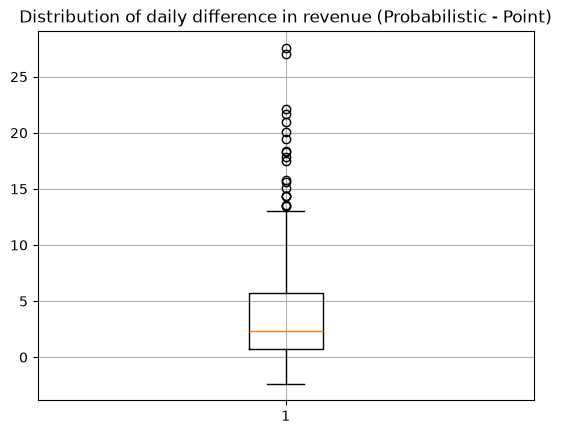

In [110]:
plt.boxplot(df_results["difference"])
plt.grid(True)
plt.title('Distribution of daily difference in revenue (Probabilistic - Point)')
plt.show()